<table>
    <tr>
        <td style="text-align:left">
            <img src="https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcR9ItLTT_F-3Q30cu7ZCCoKmuFGBt22pe7pNA" alt="Logo Universidad" width="300"/>
        </td>
        <td>
            Departamento de Ciencias de la Computación y de la Decisión<br>
            Facultad de Minas<br>
            Universidad Nacional de Colombia<br>
            Optimizacion e IA 2026-2S<br><br>
            Docente: Maria Constanza Torres Madronero<br>
            <br>
</table>

# **Regresion usando Random Forest**

In [1]:
#Importamos algunas de las librerias a usar
from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn import metrics
import numpy as np
import pandas as pd

In [2]:
#Cargar los datos - vamos a usar los datos diabetes disponibles
#en la libreria sklearn.
diabetes = datasets.load_diabetes()
#Organizamos los datos en un DataFrame de panda
#Vamos usar las primeras cuatro caracteristicas
data = pd.DataFrame({
    'age' :diabetes.data[:,0],
    'sex' :diabetes.data[:,1],
    'bmi' :diabetes.data[:,2],
    'bp' :diabetes.data[:,3],
    'diabetes' :diabetes.target
})

data.head()

,age,sex,bmi,bp,diabetes
0,0.038076,0.050680,0.061696,0.021872,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,75.0
2,0.085299,0.050680,0.044451,-0.005670,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,206.0
4,0.005383,-0.044642,-0.036385,0.021872,135.0


In [3]:
X = data[['age', 'sex', 'bmi', 'bp']] #Muestras
y = data['diabetes'] #Valor a estimar

#Seleccionamos 70% de muestras para entrenamiento y 30% para prueba
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.3)

In [4]:
#Regresion basada en Random Forest empleando parametros fijos
from sklearn.ensemble import RandomForestRegressor
#Inicialización
regr = RandomForestRegressor(n_estimators=100, # arboles
                             max_depth=3) # profundidad de los arboles
#Entrenamiento
regr.fit(X_train,y_train)
#Una vez entrenado el modelo, predecimos los valores
y_pred = regr.predict(X_test)
#Evaluamos el desempeño
print("R2: ", metrics.r2_score(y_test,y_pred))

R2:  0.33384481364660323


# Selección de hiperparametros con GA

In [ ]:
#Instalamos la libreria en la sesión
#!pip install pygad

In [5]:
#Importamos la libreria
import pygad

In [9]:
#Definicion de la funcion Fitness
#Vamos a usar validación cruzada para la selección del modelo
from sklearn.model_selection import cross_val_score

def fitness_func(ga_instance, solution, solution_idx):
    """
    Evalúa la calidad de la combinación de hiperparámetros.
    Calcula el Coeficiente de Determinación (R²) mediante validación cruzada.
    """
    # Decodificación de los genes del cromosoma
    n_estimators = int(np.round(solution[0])) 
    max_depth = int(np.round(solution[1])) # cómo vamos a elegir el cromosoma --> si son más parámetros, ver cómo introducirlos 

    # Instanciación del modelo con la configuración genética actual
    model = RandomForestRegressor(
        n_estimators=n_estimators,
        max_depth=max_depth
    )

    # Evaluación mediante Validación Cruzada de 3 pliegues (3-Fold CV)
    scores = cross_val_score(model, X_train, y_train, cv=3, scoring='r2', n_jobs=-1)
    r2_promedio = np.mean(scores)

    # Evitar valores negativos o extremadamente bajos que rompan la escala de selección
    fitness = max(r2_promedio, 1e-4) 
    return fitness

espacio de busqueda

al menos 10 árboles (menos no tiene sentido) a 300 arboles, paso 1 en 1 



In [7]:
# Configuracion del espacio de busqueda
# Definimos el tipo de dato y las restricciones para cada gen individualmente

gene_space = [
    {'low': 10, 'high': 300, 'step': 1},        # n_estimators
    {'low': 3, 'high': 30, 'step': 1},         # max_depth
]

#Dimension del gen: 2 en este caso, 2 genes 
num_genes = len(gene_space)

variables categóricas: ejemplo: funcion relu, tahn, las convierto a numero (relu, tahn) y le digo que se mueva de 1 a 2 

In [10]:
#Instancia del modelo
ga_instance = pygad.GA(
    num_generations=30,
    num_parents_mating=4,
    fitness_func=fitness_func,
    sol_per_pop=10,
    num_genes=num_genes,
    gene_space=gene_space,
    parent_selection_type="tournament", # Selección por torneo para mantener presión selectiva
    crossover_type="uniform",          # Cruce uniforme para preservar la independencia de hiperparámetros
    mutation_type="random",            # Mutación aleatoria en los rangos definidos
    keep_parents=1                     # Elitismo: preserva al mejor padre en la siguiente generación
)

#Entrenamiento
ga_instance.run()

c:\Users\50649\.conda\envs\ia_opt\Lib\site-packages\pygad\utils\validation.py:406: UserWarning: mutation_percent_genes selects fewer than one gene. mutation_num_genes is set to 1.
  warnings.warn('mutation_percent_genes selects fewer than one gene. mutation_num_genes is set to 1.')
c:\Users\50649\.conda\envs\ia_opt\Lib\site-packages\pygad\utils\validation.py:459: UserWarning: keep_elitism (=1) takes precedence over keep_parents (=1). Set keep_elitism=0 to retain parents instead.
  warnings.warn(f'keep_elitism (={self.keep_elitism}) takes precedence over keep_parents (={self.keep_parents}). Set keep_elitism=0 to retain parents instead.')


In [11]:
#Obtenemos la solución optima
solucion_optima, fitness_optimo, idx_solucion_optima = ga_instance.best_solution()

print(f"R²: {fitness_optimo}")
print(f"n_estimators:      {int(solucion_optima[0])}")
print(f"max_depth:         {int(solucion_optima[1])}")

R²: 0.3528299779285325
n_estimators:      100
max_depth:         3


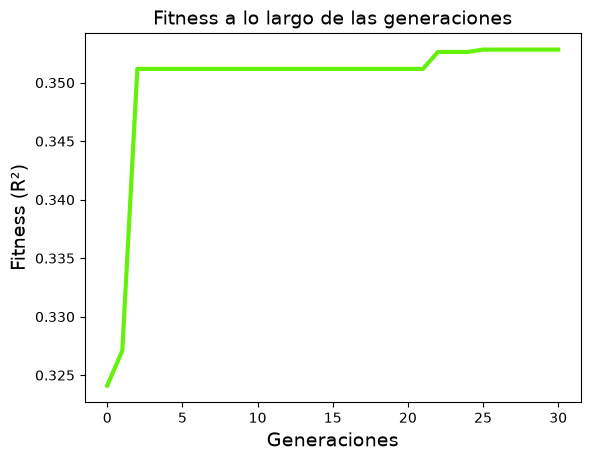

In [12]:
fig = ga_instance.plot_fitness(title="Fitness a lo largo de las generaciones", xlabel="Generaciones", ylabel="Fitness (R²)")

hay muchas generaciones donde no cambia 